In [1]:
import os
import subprocess as sp
import json
from urllib.request import Request, urlopen
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool
load_dotenv()

# os.environ["LANG_SEARCH_API_KEY"] = os.getenv("LANG_SEARCH_API_KEY")
LANG_SEARCH_API_KEY = os.getenv("LANG_SEARCH_API_KEY")
os.environ["GEMINI_API_KEY"] = os.getenv("GEMINI_API_KEY")

model = init_chat_model(
    model="gemini-3.1-flash-lite",
    model_provider="google_genai"
)


# Summarization middleware

In [19]:
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents.middleware import SummarizationMiddleware
from langchain.messages import HumanMessage, AIMessage, SystemMessage

def calc(expression:str)->str:
    """Evaluate Mathematical expression"""
    return str(eval(expression))

agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=model,
            trigger=("messages",10),
            keep=("messages",4)
        )
    ]
)
print(agent)

In [16]:
config1 = {"configurable": {"thread_id": "001"}}
config2 = {"configurable": {"thread_id": "002"}}

In [ ]:
que=[
    "What is 25 + 37?",
    "What is 144 / 12?",
    "What is 15 * 8?",
    "What is 125 - 48?",
    "What is 2 raised to the power of 10?"
]

In [ ]:
for q in que:
    response = agent.invoke({"messages":[HumanMessage(content=q)]}, config=config1)
    print(f"Message {response}")
    print(f"Message: {len(response['messages'])}")

Message {'messages': [HumanMessage(content='What is 25 + 37?', additional_kwargs={}, response_metadata={}, id='c168fd7a-25b8-4fe1-9278-fc33acb49d2f'), AIMessage(content=[{'type': 'text', 'text': '25 + 37 = 62', 'extras': {'signature': 'EpwBCpkBAWkUfRNsB+ANehcoJC/gMitqXCKlC5xFFOXB7+dabcpuEZHHTeYpHjciKt7gNEoeP3lI7PVBiM4C3ylEIl85Yq9xseI4qrgRB8zrjtaypG+wiQlulkx0nwEpapy0VOtszuC6A+WOo5fURZZQvbg6Wt88pDaqDvVc8lu7Vv98hA9mzrCriLy3rOojmXIHj44KEUBlV7wbK17i'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1eee6-6f45-7400-8b70-7beca4dcf326-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 10, 'total_tokens': 21, 'input_token_details': {'cache_read': 0}})]}
Message: 2
Message {'messages': [HumanMessage(content='What is 25 + 37?', additional_kwargs={}, response_metadata={}, id='c168fd7a-25b8-4fe1-9278-fc33acb49d2f'), AIMessage

# Token size


In [26]:
def calc(expression:str)->str:
    """Evaluate Mathematical expression"""
    return str(eval(expression))

agent = create_agent(
    model=model,
    # checkpointer=InMemorySaver(),
    tools=[calc],
    middleware=[
        SummarizationMiddleware(
            model=model,
            trigger=("tokens",550),
            keep=("tokens",200 )
        )
    ]
)
print(agent)

In [27]:
# Token counter (approximate)
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4  # 4 chars ≈ 1 token

for q in que:
    response = agent.invoke({"messages":[HumanMessage(content=q)]}, config=config2)

    tokens = count_tokens(response["messages"])

    print(f"{q}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{response['messages']}")

What is 25 + 37?: ~75 tokens, 4 messages
[HumanMessage(content='What is 25 + 37?', additional_kwargs={}, response_metadata={}, id='d05ee12e-9a65-4b4b-9c65-ebceefb81195'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'calc', 'arguments': '{"expression": "25 + 37"}'}, '__gemini_function_call_thought_signatures__': {'call_13796351758059671456': 'EpwBCpkBAWkUfRMdTmLOo4ryWjwqV/at8whSLfiTLiE4PXAYPX4QAUVWd/M2Ew2erXg+eaMsyWKuE3MZGc+lAc4m8xtiZMxo6uhhaZb3R4HjAH5oO2YUQLUKdhLtO5BsHXxwxs7MQUERKKuJ0SDkAmt9dAhUqmMH6YsZNg0qD2pULX9Eg+GkdNV/M7m7WAEk6+eEexJAUiUhXW1xFVU0'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1ef64-0bec-764d-a6b9-461931c7450f-0', tool_calls=[{'name': 'calc', 'args': {'expression': '25 + 37'}, 'id': 'call_13796351758059671456', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 49, 'output_tokens': 19, 'total_tokens': 68, '

# HumanInTheLoop

In [28]:
@tool
def read_email(email_id:str)->str:
    """To read emails of the given email id"""
    return f"Email content for id {email_id}"


@tool
def send_email(recipient_id:str, subject:str, body:str):
    """Tool to send an email"""
    return f"Email sended to {recipient_id}"

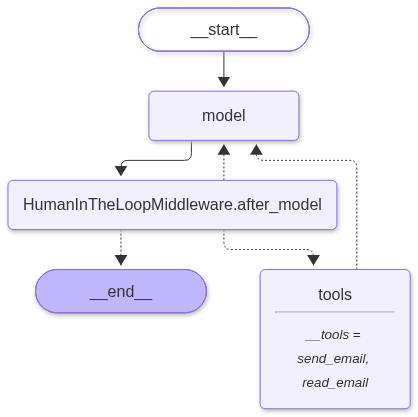

In [ ]:
from langchain.agents.middleware import HumanInTheLoopMiddleware

agent = create_agent(
    model=model,
    tools=[send_email, read_email],
    checkpointer=InMemorySaver(),
    debug=True,
    middleware=[HumanInTheLoopMiddleware(
        interrupt_on={
            "send_email":{
                "allowed_decisions":["approve","reject","edit"]
            },
            "read_email":True
        }
    )]
)
agent

In [32]:
result = agent.invoke({
    "messages":[HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.")]
},config=config2)
result

{'messages': [HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.", additional_kwargs={}, response_metadata={}, id='ff7b97f2-3e52-43f5-8393-a47cbb7d4ab6'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email', 'arguments': '{"body": "hi.", "subject": "Hello", "recipient_id": "sana@gmail.com"}'}, '__gemini_function_call_thought_signatures__': {'call_3281964363207589701': 'EpwBCpkBAWkUfRPKBWLU0urzFkrEYRcRec5G3uSI3LqefGlaG2O0OzpHiQtcmR360Sg/oDdxbMamx7MekgUGX9NPZjTF76kR56D95fGcrWTxHtUgg1ArnvjzHK+6W+u1m0AXTzmBn7mYyRByanNL4u9C+uxOXjAVaAdUREoUoOW/ELPol4KEDxMlo4936wclD8484Qv90zn3u7gSKYqa'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1ef7c-4414-703b-a303-92e8620a9f32-0', tool_calls=[{'name': 'send_email', 'args': {'body': 'hi.', 'subject': 'Hello', 'recipient_id': 'sana@gmail.com'}, 'id': 'call_3281964363207589701', 'ty

In [33]:
from langgraph.types import Command

# step 1: Approve
if "__interrupt__" in result:
    print("Approving")

    result = agent.invoke(
        Command(
            resume={
                "decisions":[
                    {"type":"approve"}
                ]
            }
        ), config=config2
    )

    print(f"Result: {result["messages"][-1].content}")

Approving
Result: [{'type': 'text', 'text': "OK. I've sent the email to sana@gmail.com.", 'extras': {'signature': 'EpwBCpkBAWkUfROG61OwKluK04mcbv0g6JgqgHmwZ3ApkDtXsXyXPptM1XKV5hftJUmgTtTcXz+NZQH+ZXMmkLmq5SwVqFYNYN32aM5Tu6136atDHx/ULPqUljCrndATwpBfYDPp6WxYKfttqbmIueES2pZcC30l2LZ5NLbTRuaLSP3w37pLjptFWVouxg/Cq9KrcPVQIrOqSDXzp0Ka'}}]


In [35]:
result = agent.invoke({
    "messages":[HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.")]
},config=config2)
result

{'messages': [HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.", additional_kwargs={}, response_metadata={}, id='ff7b97f2-3e52-43f5-8393-a47cbb7d4ab6'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email', 'arguments': '{"body": "hi.", "subject": "Hello", "recipient_id": "sana@gmail.com"}'}, '__gemini_function_call_thought_signatures__': {'call_3281964363207589701': 'EpwBCpkBAWkUfRPKBWLU0urzFkrEYRcRec5G3uSI3LqefGlaG2O0OzpHiQtcmR360Sg/oDdxbMamx7MekgUGX9NPZjTF76kR56D95fGcrWTxHtUgg1ArnvjzHK+6W+u1m0AXTzmBn7mYyRByanNL4u9C+uxOXjAVaAdUREoUoOW/ELPol4KEDxMlo4936wclD8484Qv90zn3u7gSKYqa'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1ef7c-4414-703b-a303-92e8620a9f32-0', tool_calls=[{'name': 'send_email', 'args': {'body': 'hi.', 'subject': 'Hello', 'recipient_id': 'sana@gmail.com'}, 'id': 'call_3281964363207589701', 'ty

In [36]:
# step 2: Reject
if "__interrupt__" in result:
    print("Paused Approving")

    result = agent.invoke(
        Command(
            resume={
                "decisions":[
                    {"type":"reject"}
                ]
            }
        ), config=config2
    )

    print(f"Result: {result["messages"][-1].content}")

Paused Approving
Result: [{'type': 'text', 'text': 'The request to send the email has been canceled. Please let me know if you would like me to proceed with sending it or if there is anything else I can help you with.', 'extras': {'signature': 'EpwBCpkBAWkUfRMi62VeVWeWMOtWYrGCpSzAWE3h2rPGouwoc8pjII3C7qK3BIRw/VuK7rwoAexHTPSumXvH9m5dBiFRSlt67l+HuHI8JM7JUqxuuuNzQFInWhRheBuhaf9M/CrS1xlz8zFklFGSLmfsVokBs4osuMRzdnaLGQI/TvTCug+qwL18EaoEKxYOsEKInM/QfiurFkrc8MFl'}}]


In [40]:
result = agent.invoke({
    "messages":[HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.")]
},config=config2)
result

{'messages': [HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.", additional_kwargs={}, response_metadata={}, id='ff7b97f2-3e52-43f5-8393-a47cbb7d4ab6'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email', 'arguments': '{"body": "hi.", "subject": "Hello", "recipient_id": "sana@gmail.com"}'}, '__gemini_function_call_thought_signatures__': {'call_3281964363207589701': 'EpwBCpkBAWkUfRPKBWLU0urzFkrEYRcRec5G3uSI3LqefGlaG2O0OzpHiQtcmR360Sg/oDdxbMamx7MekgUGX9NPZjTF76kR56D95fGcrWTxHtUgg1ArnvjzHK+6W+u1m0AXTzmBn7mYyRByanNL4u9C+uxOXjAVaAdUREoUoOW/ELPol4KEDxMlo4936wclD8484Qv90zn3u7gSKYqa'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1ef7c-4414-703b-a303-92e8620a9f32-0', tool_calls=[{'name': 'send_email', 'args': {'body': 'hi.', 'subject': 'Hello', 'recipient_id': 'sana@gmail.com'}, 'id': 'call_3281964363207589701', 'ty

In [41]:
# step 3: Edit
if "__interrupt__" in result:
    print("Paused Approving")

    result = agent.invoke(
        Command(
            resume={
                "decisions":[
                    {
                        "type":"edit",
                        "edited_action":{
                            "name":"send_email",
                            "args":{
                                "recipient":"new@email.com",
                                "subject":"new title",
                                "body":"new body"
                            }
                        }
                    }
                ]
            }
        ), config=config2
    )

    print(f"Result: {result['messages'][-1].content}")

Paused Approving
Result: [{'type': 'text', 'text': 'I apologize, but I am unable to complete this request. The system is encountering persistent errors when attempting to send emails to that recipient. Please double-check the email address or try again later.', 'extras': {'signature': 'EpwBCpkBAWkUfRNzBB1j0GpPsllfqk40uaAy/rN867anSjCzpx7AwOAuN14f6/zJ/5E/5RRFP6uaZMcfHhcYC2hLyvx6ZEuM4CG6eiK2tsGvsKDSD/c79XabL/R6Qwj6WR8HgGNXj/K21xG99UfkRDfUKMTBh2GquujrKUkLDH04dAN87TtSEm3I0BNEdHRMuRXBmlxO1jTsmCF+MPZ4'}}]


In [42]:
result

{'messages': [HumanMessage(content="Send email to sana@gmail.com with a subject 'Hello' and body 'hi.", additional_kwargs={}, response_metadata={}, id='ff7b97f2-3e52-43f5-8393-a47cbb7d4ab6'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email', 'arguments': '{"body": "hi.", "subject": "Hello", "recipient_id": "sana@gmail.com"}'}, '__gemini_function_call_thought_signatures__': {'call_3281964363207589701': 'EpwBCpkBAWkUfRPKBWLU0urzFkrEYRcRec5G3uSI3LqefGlaG2O0OzpHiQtcmR360Sg/oDdxbMamx7MekgUGX9NPZjTF76kR56D95fGcrWTxHtUgg1ArnvjzHK+6W+u1m0AXTzmBn7mYyRByanNL4u9C+uxOXjAVaAdUREoUoOW/ELPol4KEDxMlo4936wclD8484Qv90zn3u7gSKYqa'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1ef7c-4414-703b-a303-92e8620a9f32-0', tool_calls=[{'name': 'send_email', 'args': {'body': 'hi.', 'subject': 'Hello', 'recipient_id': 'sana@gmail.com'}, 'id': 'call_3281964363207589701', 'ty